### **Logistic Regression: Binary and Multiclass Classification**

This notebook picks up right where the Linear Regression notebook left off, but for **Classification** instead of Regression. We'll cover:

1. Why Linear Regression fails as a classifier, and the **Sigmoid function** that fixes it
2. The Logistic Regression model, its **Cost Function (Log Loss)**, and **Gradient Descent**
3. A full **binary classification** example — from scratch and with `scikit-learn`
4. Evaluation metrics for binary classifiers (confusion matrix, precision/recall, ROC-AUC)
5. Extending to **multiclass classification** — One-vs-Rest and Softmax (Multinomial) Regression
6. Evaluation metrics for multiclass classifiers

Every concept is shown graphically, not just algebraically.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')
np.random.seed(42)


#### **1. Why Not Just Use Linear Regression for Classification?**

Suppose we want to predict whether a student **passes (1)** or **fails (0)** an exam, based on hours studied. What happens if we just fit an ordinary straight line to this 0/1 data?

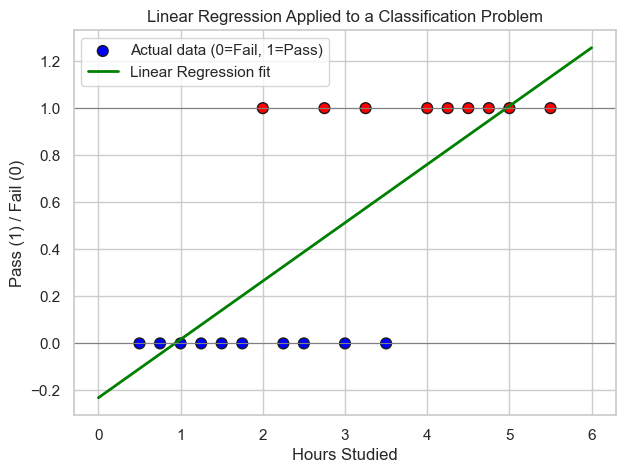

Predicted value at 0 hours studied: -0.23   (should be a probability, but it's negative!)
Predicted value at 6 hours studied: 1.26   (a 'probability' greater than 1!)


In [2]:
hours = np.array([0.5,0.75,1,1.25,1.5,1.75,2,2.25,2.5,2.75,3,3.25,3.5,4,4.25,4.5,4.75,5,5.5])
passed = np.array([0,0,0,0,0,0,1,0,0,1,0,1,0,1,1,1,1,1,1])

from sklearn.linear_model import LinearRegression

lin_model = LinearRegression().fit(hours.reshape(-1,1), passed)
xs = np.linspace(0, 6, 100).reshape(-1,1)
lin_pred = lin_model.predict(xs)

plt.figure(figsize=(7,5))
plt.scatter(hours, passed, c=passed, cmap='bwr', edgecolor='k', s=60, label='Actual data (0=Fail, 1=Pass)')
plt.plot(xs, lin_pred, color='green', linewidth=2, label='Linear Regression fit')
plt.axhline(0, color='gray', linewidth=0.8); plt.axhline(1, color='gray', linewidth=0.8)
plt.xlabel('Hours Studied'); plt.ylabel('Pass (1) / Fail (0)')
plt.title('Linear Regression Applied to a Classification Problem')
plt.legend()
plt.show()

print(f"Predicted value at 0 hours studied: {lin_model.predict([[0]])[0]:.2f}   (should be a probability, but it's negative!)")
print(f"Predicted value at 6 hours studied: {lin_model.predict([[6]])[0]:.2f}   (a 'probability' greater than 1!)")


**The problem:** a straight line has no upper or lower bound, so it happily predicts values below 0 or above 1 — meaningless if we want to interpret the output as a **probability**. We need a function that squashes any input into the range $(0, 1)$. That's exactly what the **Sigmoid function** does.

#### **2. The Sigmoid (Logistic) Function**

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

- As $z \to +\infty$, $\sigma(z) \to 1$
- As $z \to -\infty$, $\sigma(z) \to 0$
- At $z = 0$, $\sigma(z) = 0.5$ exactly

This gives the classic "S-shaped" curve — any real number goes in, and a value between 0 and 1 comes out, which we can interpret as a probability.

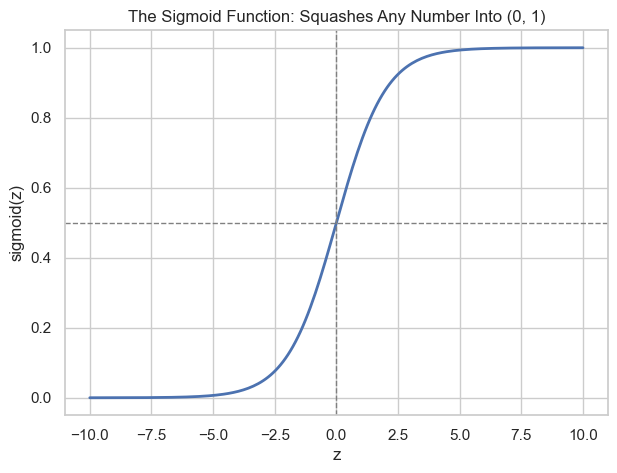

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 200)

plt.figure(figsize=(7,5))
plt.plot(z, sigmoid(z), linewidth=2)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1)
plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.xlabel('z'); plt.ylabel('sigmoid(z)')
plt.title('The Sigmoid Function: Squashes Any Number Into (0, 1)')
plt.show()


#### **3. The Logistic Regression Model**

Just like Linear Regression, we first compute a linear combination of the inputs:

$$z = b_0 + b_1x_1 + b_2x_2 + \dots + b_nx_n$$

But instead of using $z$ directly as the prediction, we pass it through the sigmoid function:

$$\hat{y} = P(y=1 \mid x) = \sigma(z) = \frac{1}{1+e^{-z}}$$

**Making a final decision:** since $\hat{y}$ is a probability, we apply a threshold (usually 0.5) to get an actual class prediction:

$$\text{predicted class} = \begin{cases} 1 & \text{if } \hat{y} \geq 0.5 \\ 0 & \text{if } \hat{y} < 0.5 \end{cases}$$

**The Decision Boundary:** notice $\hat{y} \geq 0.5$ happens exactly when $z \geq 0$ (since $\sigma(0)=0.5$). So the boundary between predicted classes is simply $z = 0$, i.e. $b_0 + b_1x_1 + \dots = 0$ — a **straight line** (or flat plane/hyperplane with more features). Logistic Regression is a **linear classifier**.

#### **4. The Cost Function — Log Loss (Binary Cross-Entropy)**

**Why not reuse MSE from Linear Regression?** Plugging the sigmoid into the MSE formula produces a **non-convex** cost surface full of local minima — Gradient Descent could easily get stuck without ever reaching the true best solution. We need a cost function that stays convex (bowl-shaped) even with the sigmoid inside it.

**Log Loss** does exactly that:

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i\log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)\Big]$$

**Intuition:** for each sample, only ONE of the two terms is ever "active" (the other multiplies by 0):
- If the true label $y_i = 1$: cost is $-\log(\hat{y}_i)$ — this blows up toward infinity if the model confidently predicted close to 0 (badly wrong), and shrinks toward 0 if it predicted close to 1 (correct).
- If the true label $y_i = 0$: cost is $-\log(1-\hat{y}_i)$ — same idea in reverse.

So Log Loss **heavily punishes confident wrong predictions**, which is exactly the behavior we want.

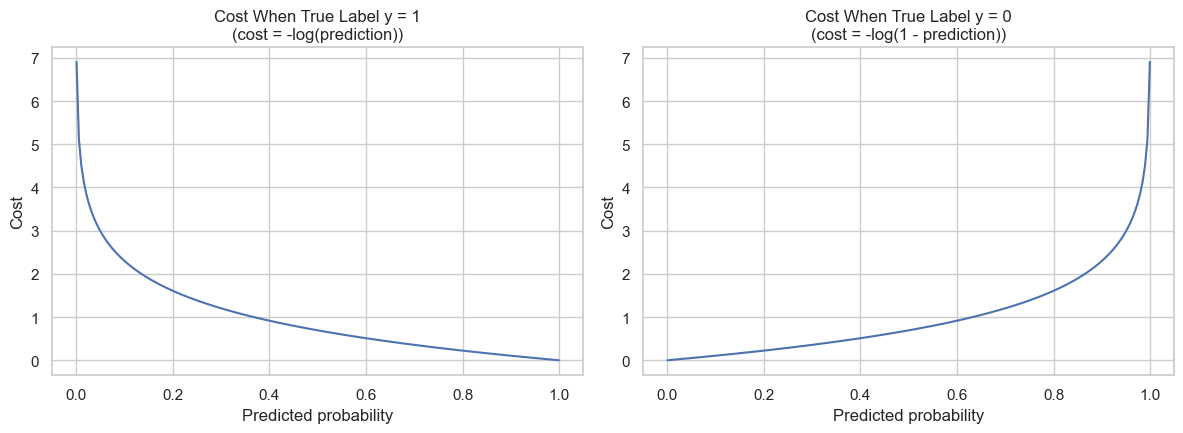

In [4]:
p = np.linspace(0.001, 0.999, 200)

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
axes[0].plot(p, -np.log(p))
axes[0].set_title('Cost When True Label y = 1\n(cost = -log(prediction))')
axes[0].set_xlabel('Predicted probability'); axes[0].set_ylabel('Cost')

axes[1].plot(p, -np.log(1-p))
axes[1].set_title('Cost When True Label y = 0\n(cost = -log(1 - prediction))')
axes[1].set_xlabel('Predicted probability'); axes[1].set_ylabel('Cost')

plt.tight_layout()
plt.show()


#### **5. Gradient Descent for Logistic Regression**

Remarkably, after working through the calculus (the derivative of Log Loss combined with the sigmoid's own derivative), the gradient simplifies to **exactly the same form** as Linear Regression's gradient:

$$\frac{\partial J}{\partial b_j} = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i - y_i)\,x_{ij}$$

So the update rule is identical in form to Linear Regression:

$$b_j := b_j - \alpha \cdot \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i - y_i)\,x_{ij}$$

**The only difference:** $\hat{y}_i$ here means $\sigma(z_i)$ (passed through the sigmoid), not the raw linear output. Same update mechanics, different prediction function feeding into it.

In [5]:
def logistic_gradient_descent(X, y, learning_rate=0.5, iterations=5000):
    m, n = X.shape
    X_b = np.c_[np.ones((m, 1)), X]
    theta = np.zeros(n + 1)
    cost_history = []

    for _ in range(iterations):
        z = X_b.dot(theta)
        predictions = sigmoid(z)
        errors = predictions - y
        gradients = (1 / m) * X_b.T.dot(errors)
        theta -= learning_rate * gradients

        # Log Loss, with a tiny epsilon to avoid log(0)
        eps = 1e-10
        cost = -np.mean(y*np.log(predictions+eps) + (1-y)*np.log(1-predictions+eps))
        cost_history.append(cost)

    return theta, cost_history


#### **6. Binary Classification — Full Worked Example**

Back to our "Hours Studied &rarr; Pass/Fail" data from Section 1. Let's fit it properly this time, using our from-scratch Gradient Descent.

In [6]:
theta, cost_history = logistic_gradient_descent(hours.reshape(-1,1), passed, learning_rate=0.5, iterations=5000)
b0, b1 = theta
print(f"From-scratch result: b0 = {b0:.4f}, b1 = {b1:.4f}")

decision_boundary = -b0 / b1
print(f"Decision boundary at: {decision_boundary:.2f} hours studied")


From-scratch result: b0 = -5.2186, b1 = 1.7847
Decision boundary at: 2.92 hours studied


In [7]:
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression()
sk_model.fit(hours.reshape(-1,1), passed)
print(f"sklearn result: b0 = {sk_model.intercept_[0]:.4f}, b1 = {sk_model.coef_[0][0]:.4f}")


sklearn result: b0 = -3.7315, b1 = 1.2643


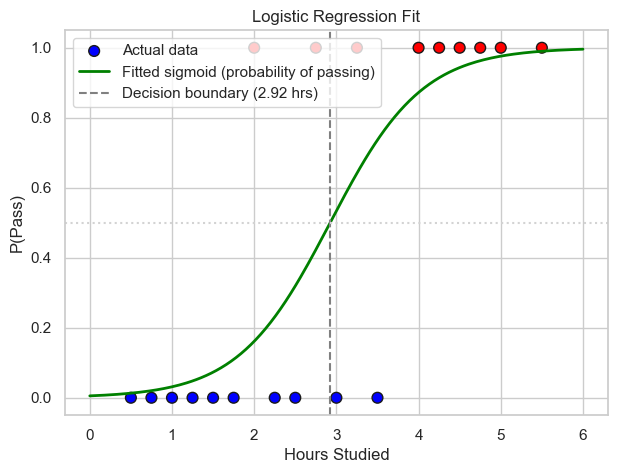

In [8]:
plt.figure(figsize=(7,5))
plt.scatter(hours, passed, c=passed, cmap='bwr', edgecolor='k', s=60, label='Actual data')
xs = np.linspace(0, 6, 200)
plt.plot(xs, sigmoid(b0 + b1*xs), color='green', linewidth=2, label='Fitted sigmoid (probability of passing)')
plt.axvline(decision_boundary, color='gray', linestyle='--', label=f'Decision boundary ({decision_boundary:.2f} hrs)')
plt.axhline(0.5, color='lightgray', linestyle=':')
plt.xlabel('Hours Studied'); plt.ylabel('P(Pass)')
plt.title('Logistic Regression Fit')
plt.legend()
plt.show()


**6.1 Visualizing a Decision Boundary With 2 Features**

With 2 features, the decision boundary ($z=0$) becomes a straight **line** cutting through the 2D feature space, rather than a single point on a 1D number line.

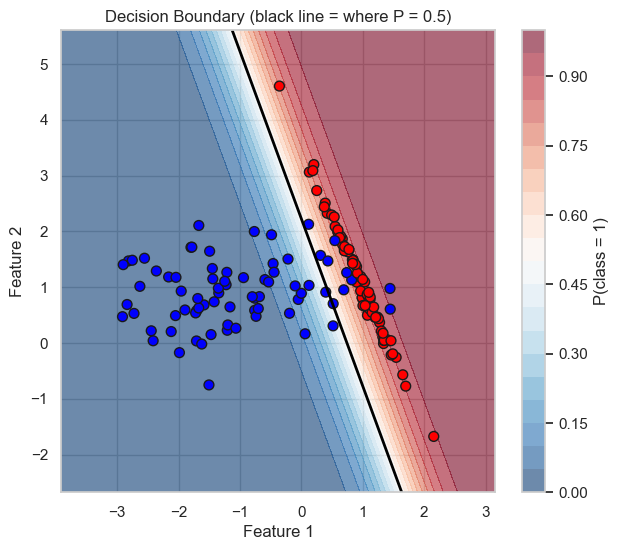

In [9]:
from sklearn.datasets import make_classification

X2, y2 = make_classification(n_samples=150, n_features=2, n_redundant=0, n_informative=2,
                              n_clusters_per_class=1, random_state=42)
clf2 = LogisticRegression().fit(X2, y2)

xx, yy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 200),
                      np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 200))
Z = clf2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:,1].reshape(xx.shape)

plt.figure(figsize=(7,6))
plt.contourf(xx, yy, Z, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(label='P(class = 1)')
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)   # the decision boundary itself
plt.scatter(X2[:,0], X2[:,1], c=y2, cmap='bwr', edgecolor='k', s=50)
plt.title('Decision Boundary (black line = where P = 0.5)')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()


#### **7. Evaluating a Binary Classifier**

**7.1 The Confusion Matrix**

A 2x2 table comparing actual vs predicted classes:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | True Negative (TN) | False Positive (FP) |
| **Actual 1** | False Negative (FN) | True Positive (TP) |

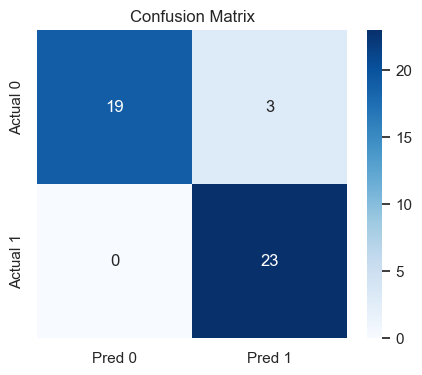

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X2, y2, test_size=0.3, random_state=42)
clf3 = LogisticRegression().fit(X_train, y_train)
y_pred = clf3.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0','Pred 1'], yticklabels=['Actual 0','Actual 1'])
plt.title('Confusion Matrix')
plt.show()


**7.2 Precision, Recall, F1-Score**

$$\text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN} \qquad \text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad F1 = \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision}+\text{Recall}}$$

- **Precision** → "Of everything I predicted positive, how much was actually positive?" (matters when false positives are costly)
- **Recall** → "Of everything that was actually positive, how much did I catch?" (matters when false negatives are costly, e.g. disease detection)
- **F1** → a single number balancing both.

In [11]:
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       1.00      0.86      0.93        22
           1       0.88      1.00      0.94        23

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



**7.3 The ROC Curve and AUC**

The ROC curve plots the **True Positive Rate** against the **False Positive Rate** at every possible decision threshold (not just 0.5) — showing the full tradeoff between catching positives and raising false alarms. **AUC** (Area Under the Curve) condenses this into one number: 1.0 = perfect classifier, 0.5 = no better than random guessing.

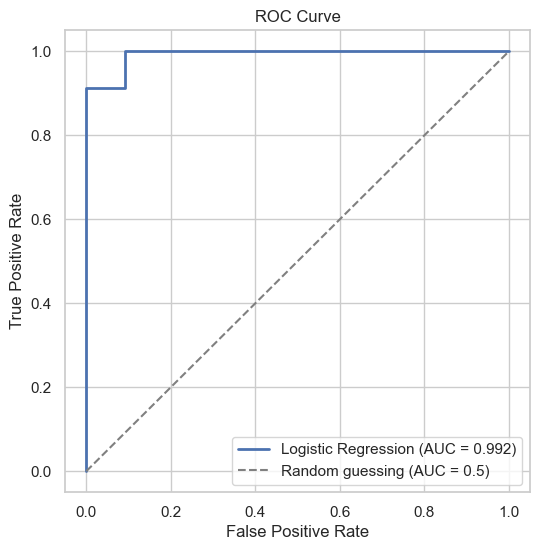

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

y_proba = clf3.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, linewidth=2, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random guessing (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


#### **8. Multiclass Classification — Extending Logistic Regression**

What if there are **more than 2** classes (e.g., 3 species of flowers)? Plain Logistic Regression only outputs one probability for "class 1 vs not" — we need a strategy to extend it.

**8.1 Strategy 1 — One-vs-Rest (OvR / One-vs-All)**

Train **K separate binary classifiers** (one per class), where classifier $k$ learns to distinguish "class $k$" vs "everything else." To predict, run all K classifiers and pick whichever one outputs the **highest** probability.

**8.2 Strategy 2 — Softmax (Multinomial) Regression**

Instead of K independent binary problems, fit **one single model** that directly outputs a full probability distribution over all K classes at once, using the **Softmax function**:

$$P(y=k \mid x) = \frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}$$

This is the direct generalization of the sigmoid to multiple classes — notice that with only $K=2$ classes, softmax reduces back to exactly the sigmoid function. The outputs across all K classes always sum to exactly 1.

`scikit-learn`'s `LogisticRegression` uses Softmax/multinomial fitting **by default** whenever there are more than 2 classes. To explicitly do One-vs-Rest instead, wrap it with `OneVsRestClassifier`.

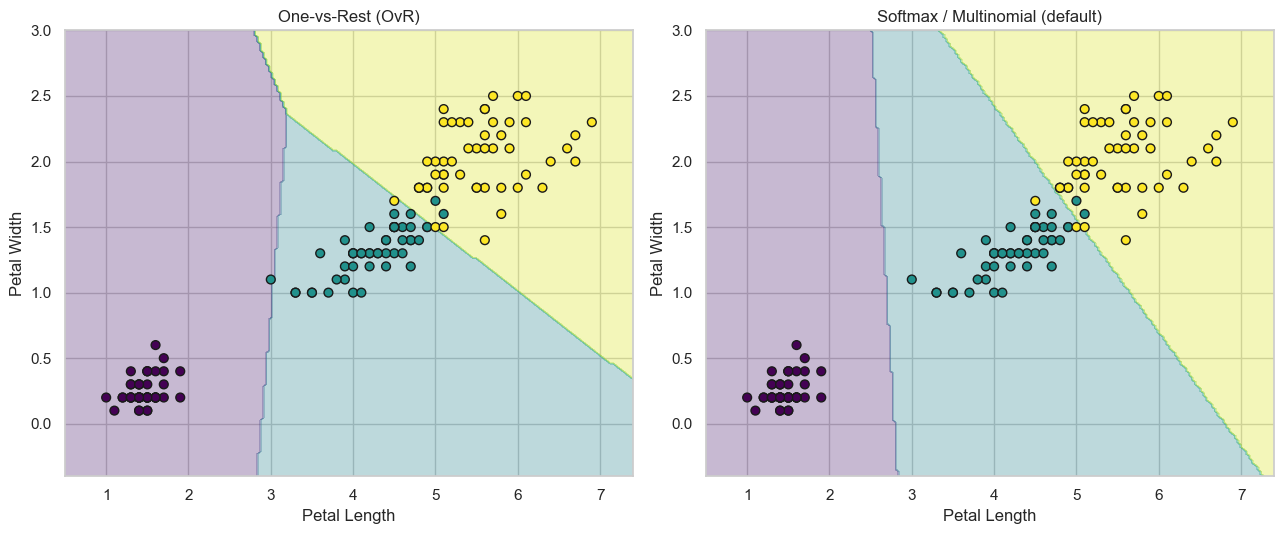

In [13]:
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier

iris = load_iris()
X3 = iris.data[:, 2:4]   # just petal length & width, so we can plot in 2D
y3 = iris.target

clf_ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000)).fit(X3, y3)
clf_softmax = LogisticRegression(max_iter=1000).fit(X3, y3)   # multinomial/softmax by default

xx3, yy3 = np.meshgrid(np.linspace(X3[:,0].min()-0.5, X3[:,0].max()+0.5, 200),
                        np.linspace(X3[:,1].min()-0.5, X3[:,1].max()+0.5, 200))
Z_ovr = clf_ovr.predict(np.c_[xx3.ravel(), yy3.ravel()]).reshape(xx3.shape)
Z_softmax = clf_softmax.predict(np.c_[xx3.ravel(), yy3.ravel()]).reshape(xx3.shape)

fig, axes = plt.subplots(1, 2, figsize=(13,5.5))
for ax, Z, title in zip(axes, [Z_ovr, Z_softmax], ['One-vs-Rest (OvR)', 'Softmax / Multinomial (default)']):
    ax.contourf(xx3, yy3, Z, alpha=0.3, cmap='viridis')
    ax.scatter(X3[:,0], X3[:,1], c=y3, cmap='viridis', edgecolor='k', s=40)
    ax.set_title(title)
    ax.set_xlabel('Petal Length'); ax.set_ylabel('Petal Width')
plt.tight_layout()
plt.show()


**💡 Notice:** both strategies produce very similar decision boundaries here, with only small differences near the overlapping versicolor/virginica region. In practice, softmax is the more common default in modern libraries (and is what `scikit-learn` now uses automatically), while OvR is simpler to reason about and still useful when you want independent per-class probabilities.

In [14]:
# Softmax output always sums to exactly 1 across all classes
sample = X3[0].reshape(1, -1)
proba = clf_softmax.predict_proba(sample)
print("Class probabilities:", dict(zip(iris.target_names, proba[0].round(4))))
print("Sum of probabilities:", proba.sum())


Class probabilities: {np.str_('setosa'): np.float64(0.9798), np.str_('versicolor'): np.float64(0.0202), np.str_('virginica'): np.float64(0.0)}
Sum of probabilities: 0.9999999999999999


#### **9. Evaluating a Multiclass Classifier**

**9.1 The Multiclass Confusion Matrix**

Now a $K \times K$ grid instead of 2x2 — the diagonal shows correct predictions per class, off-diagonal cells show which classes get confused with each other.

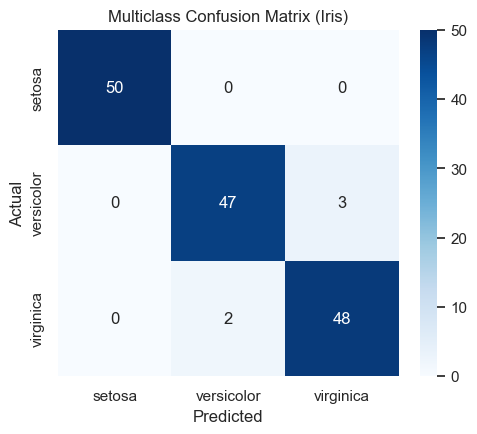

In [15]:
from sklearn.metrics import confusion_matrix

y3_pred = clf_softmax.predict(X3)
cm3 = confusion_matrix(y3, y3_pred)

plt.figure(figsize=(5.5,4.5))
sns.heatmap(cm3, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Multiclass Confusion Matrix (Iris)')
plt.show()


**9.2 Precision, Recall & F1 — Now Per Class, Plus Averages**

With more than 2 classes, precision/recall/F1 are computed **once per class** (treating that class as "positive" and all others as "negative"), then usually summarized two ways:
- **Macro average** → simple average across classes, treating every class equally regardless of size
- **Weighted average** → average weighted by how many true samples each class has (better when classes are imbalanced)

In [16]:
print(classification_report(y3, y3_pred, target_names=iris.target_names))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.96      0.94      0.95        50
   virginica       0.94      0.96      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



#### **10. Summary**

| Concept | Binary | Multiclass |
|---|---|---|
| Output function | Sigmoid: $\sigma(z) = \frac{1}{1+e^{-z}}$ | Softmax: $\frac{e^{z_k}}{\sum_j e^{z_j}}$ |
| Output | 1 probability (class 1 vs 0) | K probabilities, summing to 1 |
| Cost function | Binary Cross-Entropy (Log Loss) | Categorical Cross-Entropy |
| Decision rule | Threshold at 0.5 | Pick class with highest probability |
| Strategies | — | One-vs-Rest, or native Softmax |
| Key metrics | Precision, Recall, F1, ROC-AUC | Same metrics, per-class + macro/weighted average |

**Big picture recap:**
- Logistic Regression starts exactly like Linear Regression ($z = b_0+b_1x_1+...$), then squashes $z$ through a **Sigmoid** (binary) or **Softmax** (multiclass) to get valid probabilities.
- It uses **Log Loss**, not MSE, as its cost function — because MSE + sigmoid together would create a non-convex optimization problem.
- Despite the different cost function, **Gradient Descent's update rule looks identical** to Linear Regression's — only the definition of $\hat{y}$ changes.
- For more than 2 classes, **One-vs-Rest** trains K independent binary models, while **Softmax Regression** fits one unified model directly — `scikit-learn` defaults to the latter.